# Modelo Teórico da Máquina
**Máquina Estatística — Probabilidade e Estatística I (IFES Serra - 2026/2)**  
**Equipe:** João Victor Santos Araujo & João Victor Nascimento Ribeiro  
**Professor:** Fidelis Zanetti de Castro  

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/joaovictorsaraujo/maquina-estatistica/blob/master/notebooks/00_modelo_teorico.ipynb)

---
### Descrição do Experimento
Enumeração do espaço amostral (125 triplas), regras de pagamento, distribuição de probabilidades, esperança matemática (E[X] = -0,16) e RTP (84%).


In [1]:
# Configuração de ambiente para Google Colab e ambiente local
import sys
from pathlib import Path

# Se executando no Google Colab, clona o repositório para obter tabelas e resultados
if 'google.colab' in sys.modules:
    if not Path('resultados/tabelas').is_dir():
        !git clone https://github.com/joaovictorsaraujo/maquina-estatistica.git
        %cd maquina-estatistica

try:
    from IPython.display import display
except ImportError:
    display = print

from itertools import product
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Localiza a raiz independentemente de o VS Code usar notebooks/ ou a raiz como CWD.
atual = Path.cwd().resolve()
raiz = next(
    (p for p in (atual, *atual.parents)
     if (p / "src" / "maquina_estatistica" / "config.py").is_file()),
    None,
)
if raiz is None:
    raise FileNotFoundError(
        "Não encontrei src/maquina_estatistica/config.py. "
        "Abra este notebook dentro da pasta do repositório maquina-estatistica."
    )

# Importa as constantes do projeto original: nenhuma nova simulação é executada.
sys.path.insert(0, str(raiz / "src"))
from maquina_estatistica.config import (
    SIMBOLOS, NUM_ROLOS, CUSTO_APOSTA, PAGAMENTOS_BASE,
    TOTAL_COMBINACOES_CENTRAIS, PROBABILIDADE_TEORICA_PREMIO,
    ESPERANCA_PREMIO_BASE, ESPERANCA_LUCRO_BASE, RTP_TEORICO_BASE,
)

saida_graficos = raiz / "resultados" / "graficos" / "notebooks"
saida_graficos.mkdir(parents=True, exist_ok=True)

simbolos = tuple(SIMBOLOS)
pagamentos = dict(PAGAMENTOS_BASE)
aposta = float(CUSTO_APOSTA)

# Regras fixas do enunciado, para detectar configurações divergentes.
assert simbolos == ("A", "B", "C", "D", "E")
assert NUM_ROLOS == 3
assert np.isclose(aposta, 1.0)
assert pagamentos == {
    "A-A-A": 5.0, "B-B-B": 10.0, "C-C-C": 15.0,
    "D-D-D": 25.0, "E-E-E": 50.0,
}

print("Raiz:", raiz)
print("Gráficos serão salvos em:", saida_graficos)
print("Regras da configuração conferidas com o enunciado.")

Raiz: C:\Users\João Vitor\Downloads\maquina-estatistica-master (1)\maquina-estatistica-master
Gráficos serão salvos em: C:\Users\João Vitor\Downloads\maquina-estatistica-master (1)\maquina-estatistica-master\resultados\graficos\notebooks
Regras da configuração conferidas com o enunciado.


In [2]:
tabela_janelas = pd.DataFrame([
    {
        "Parada K": k,
        "Topo": simbolos[k],
        "Centro": simbolos[(k + 1) % len(simbolos)],
        "Base": simbolos[(k + 2) % len(simbolos)],
    }
    for k in range(len(simbolos))
])
assert tabela_janelas.loc[4, ["Topo", "Centro", "Base"]].tolist() == ["E", "A", "B"]
assert set(tabela_janelas["Centro"]) == set(simbolos)
display(tabela_janelas)

,Parada K,Topo,Centro,Base
0,0,A,B,C
1,1,B,C,D
2,2,C,D,E
3,3,D,E,A
4,4,E,A,B


In [3]:
registros = []
for k1, k2, k3 in product(range(len(simbolos)), repeat=NUM_ROLOS):
    paradas = (k1, k2, k3)
    linha = tuple(simbolos[(k + 1) % len(simbolos)] for k in paradas)
    combinacao = "-".join(linha)
    premio = float(pagamentos.get(combinacao, 0.0))
    registros.append({
        "Paradas": paradas,
        "Combinação central": combinacao,
        "Prêmio P": premio,
        "Lucro X": premio - aposta,
        "Probabilidade": 1 / (len(simbolos) ** NUM_ROLOS),
    })

df_espaco = pd.DataFrame(registros)

assert len(df_espaco) == 125 == TOTAL_COMBINACOES_CENTRAIS
assert df_espaco["Combinação central"].nunique() == 125
assert np.isclose(df_espaco["Probabilidade"].sum(), 1)
assert int((df_espaco["Prêmio P"] > 0).sum()) == 5
assert int((df_espaco["Prêmio P"] == 0).sum()) == 120
assert np.allclose(df_espaco["Lucro X"], df_espaco["Prêmio P"] - aposta)

print("Resultados possíveis:", len(df_espaco))
print("Combinações premiadas:", (df_espaco["Prêmio P"] > 0).sum())
print("Combinações sem prêmio:", (df_espaco["Prêmio P"] == 0).sum())
print("Exemplos das primeiras combinações:")
display(df_espaco.head(8))

Resultados possíveis: 125
Combinações premiadas: 5
Combinações sem prêmio: 120
Exemplos das primeiras combinações:


,Paradas,Combinação central,Prêmio P,Lucro X,Probabilidade
0,"(0, 0, 0)",B-B-B,10.0,9.0,0.008
1,"(0, 0, 1)",B-B-C,0.0,-1.0,0.008
2,"(0, 0, 2)",B-B-D,0.0,-1.0,0.008
3,"(0, 0, 3)",B-B-E,0.0,-1.0,0.008
4,"(0, 0, 4)",B-B-A,0.0,-1.0,0.008
5,"(0, 1, 0)",B-C-B,0.0,-1.0,0.008
6,"(0, 1, 1)",B-C-C,0.0,-1.0,0.008
7,"(0, 1, 2)",B-C-D,0.0,-1.0,0.008


In [4]:
categorias = [-1.0, 4.0, 9.0, 14.0, 24.0, 49.0]
rotulos = ["Sem prêmio", "AAA", "BBB", "CCC", "DDD", "EEE"]
contagens = df_espaco["Lucro X"].value_counts().reindex(categorias, fill_value=0)

df_distribuicao = pd.DataFrame({
    "Categoria": rotulos,
    "Lucro X (créditos)": categorias,
    "Prêmio P (créditos)": [0, 5, 10, 15, 25, 50],
    "Combinações (em 125)": contagens.to_numpy(dtype=int),
})
df_distribuicao["Probabilidade"] = (
    df_distribuicao["Combinações (em 125)"] / len(df_espaco)
)
df_distribuicao["Probabilidade (%)"] = 100 * df_distribuicao["Probabilidade"]
df_distribuicao["Contribuição para E[X]"] = (
    df_distribuicao["Lucro X (créditos)"] * df_distribuicao["Probabilidade"]
)
df_distribuicao["Contribuição para E[P]"] = (
    df_distribuicao["Prêmio P (créditos)"] * df_distribuicao["Probabilidade"]
)

assert df_distribuicao["Combinações (em 125)"].tolist() == [120, 1, 1, 1, 1, 1]
assert np.isclose(df_distribuicao["Probabilidade"].sum(), 1)

display(df_distribuicao.style.format({
    "Lucro X (créditos)": "{:+.0f}",
    "Prêmio P (créditos)": "{:.0f}",
    "Probabilidade": "{:.4f}",
    "Probabilidade (%)": "{:.2f}%",
    "Contribuição para E[X]": "{:+.3f}",
    "Contribuição para E[P]": "{:.3f}",
}))

,Categoria,Lucro X (créditos),Prêmio P (créditos),Combinações (em 125),Probabilidade,Probabilidade (%),Contribuição para E[X],Contribuição para E[P]
0,Sem prêmio,-1,0,120,0.9600,96.00%,-0.960,0.000
1,AAA,+4,5,1,0.0080,0.80%,+0.032,0.040
2,BBB,+9,10,1,0.0080,0.80%,+0.072,0.080
3,CCC,+14,15,1,0.0080,0.80%,+0.112,0.120
4,DDD,+24,25,1,0.0080,0.80%,+0.192,0.200
5,EEE,+49,50,1,0.0080,0.80%,+0.392,0.400


In [5]:
prob_premio = df_distribuicao.loc[
    df_distribuicao["Prêmio P (créditos)"] > 0, "Probabilidade"
].sum()
esperanca_premio = df_distribuicao["Contribuição para E[P]"].sum()
esperanca_lucro = df_distribuicao["Contribuição para E[X]"].sum()
rtp = esperanca_premio / aposta * 100
vantagem_operador = 100 - rtp
ex2 = (
    df_distribuicao["Lucro X (créditos)"].pow(2)
    * df_distribuicao["Probabilidade"]
).sum()
variancia_lucro = ex2 - esperanca_lucro**2
desvio_padrao_lucro = np.sqrt(variancia_lucro)

# Confere os cálculos independentes contra as constantes usadas pelo simulador.
assert np.isclose(prob_premio, 0.04)
assert np.isclose(prob_premio, PROBABILIDADE_TEORICA_PREMIO)
assert np.isclose(esperanca_premio, 0.84)
assert np.isclose(esperanca_premio, ESPERANCA_PREMIO_BASE)
assert np.isclose(esperanca_lucro, -0.16)
assert np.isclose(esperanca_lucro, ESPERANCA_LUCRO_BASE)
assert np.isclose(rtp, 84.0)
assert np.isclose(rtp, RTP_TEORICO_BASE)
assert variancia_lucro >= 0

resumo_teorico = pd.DataFrame([
    ["Total de combinações centrais", len(df_espaco), "combinações"],
    ["Probabilidade de prêmio", prob_premio * 100, "%"],
    ["Prêmio médio esperado E[P]", esperanca_premio, "crédito/rodada"],
    ["Lucro médio esperado E[X]", esperanca_lucro, "crédito/rodada"],
    ["RTP teórico", rtp, "%"],
    ["Vantagem esperada do operador", vantagem_operador, "%"],
    ["Variância teórica do lucro", variancia_lucro, "créditos²"],
    ["Desvio-padrão teórico do lucro", desvio_padrao_lucro, "créditos"],
], columns=["Métrica", "Valor", "Unidade"])
display(resumo_teorico.style.format({"Valor": "{:.4f}"}))

,Métrica,Valor,Unidade
0,Total de combinações centrais,125.0000,combinações
1,Probabilidade de prêmio,4.0000,%
2,Prêmio médio esperado E[P],0.8400,crédito/rodada
3,Lucro médio esperado E[X],-0.1600,crédito/rodada
4,RTP teórico,84.0000,%
5,Vantagem esperada do operador,16.0000,%
6,Variância teórica do lucro,27.0944,créditos²
7,Desvio-padrão teórico do lucro,5.2052,créditos


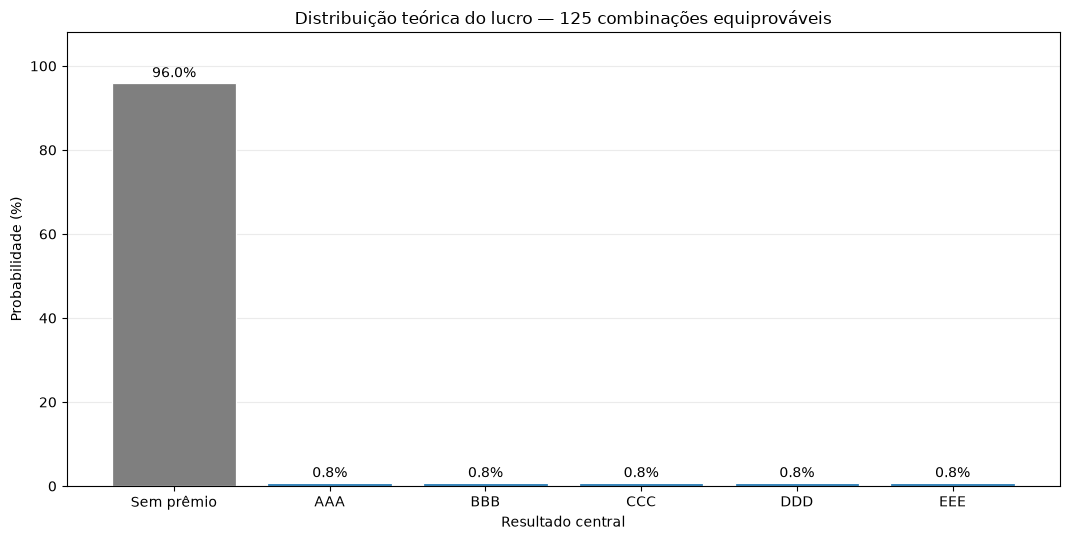

Salvo em: resultados\graficos\notebooks\modelo_teorico_distribuicao_lucro.png


In [6]:
fig, ax = plt.subplots(figsize=(10.8, 5.5))
valores = df_distribuicao["Probabilidade (%)"].to_numpy()
cores = ["tab:gray"] + ["tab:blue"] * 5
barras = ax.bar(rotulos, valores, color=cores, edgecolor="white", linewidth=0.9)
for barra, valor in zip(barras, valores):
    ax.annotate(f"{valor:.1f}%", (barra.get_x() + barra.get_width()/2, valor),
                xytext=(0, 4), textcoords="offset points", ha="center", fontsize=10)
ax.set(title="Distribuição teórica do lucro — 125 combinações equiprováveis",
       xlabel="Resultado central", ylabel="Probabilidade (%)", ylim=(0, 108))
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
fig.tight_layout()
arquivo_distribuicao = saida_graficos / "modelo_teorico_distribuicao_lucro.png"
fig.savefig(arquivo_distribuicao, dpi=200, bbox_inches="tight")
plt.show()
print("Salvo em:", arquivo_distribuicao.relative_to(raiz))

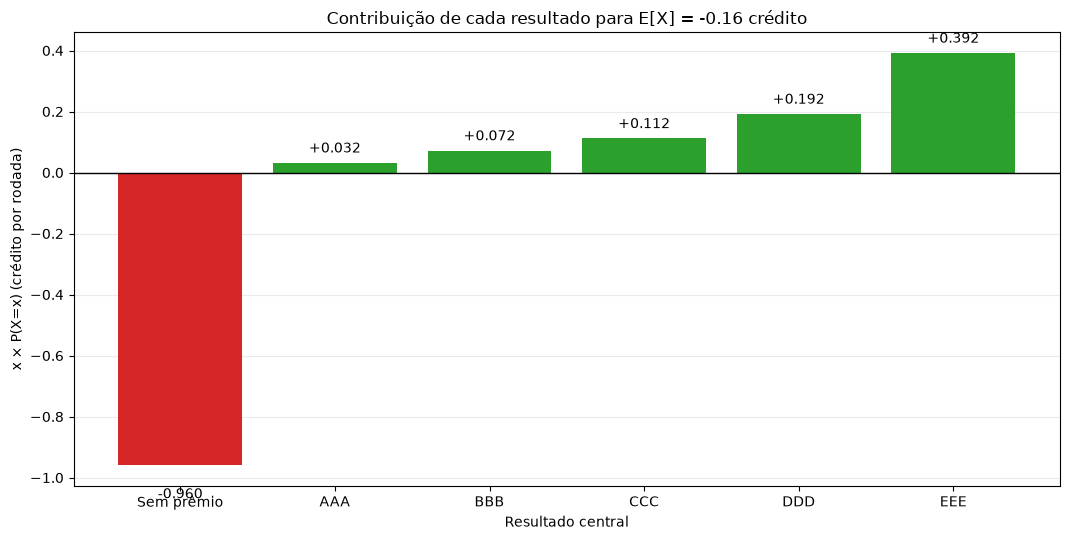

Salvo em: resultados\graficos\notebooks\modelo_teorico_contribuicoes_esperanca.png


In [7]:
contribuicoes = df_distribuicao["Contribuição para E[X]"].to_numpy()
fig, ax = plt.subplots(figsize=(10.8, 5.5))
barras = ax.bar(rotulos, contribuicoes,
                color=["tab:red" if x < 0 else "tab:green" for x in contribuicoes])
ax.axhline(0, color="black", linewidth=1)
for barra, valor in zip(barras, contribuicoes):
    deslocamento = -16 if valor < 0 else 5
    ax.annotate(f"{valor:+.3f}", (barra.get_x()+barra.get_width()/2, valor),
                xytext=(0, deslocamento), textcoords="offset points",
                ha="center", fontsize=10, va="top" if valor < 0 else "bottom")
ax.set(title=f"Contribuição de cada resultado para E[X] = {esperanca_lucro:+.2f} crédito",
       xlabel="Resultado central", ylabel="x × P(X=x) (crédito por rodada)")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
fig.tight_layout()
arquivo_contribuicao = saida_graficos / "modelo_teorico_contribuicoes_esperanca.png"
fig.savefig(arquivo_contribuicao, dpi=200, bbox_inches="tight")
plt.show()
print("Salvo em:", arquivo_contribuicao.relative_to(raiz))

In [8]:
arquivo_e1 = raiz / "resultados" / "tabelas" / "e1_frequencias.csv"
if arquivo_e1.is_file():
    dados_e1 = pd.read_csv(arquivo_e1)
    colunas = {"lucro_x", "prob_teorica"}
    assert colunas.issubset(dados_e1.columns), (
        "O CSV do E1 não contém as colunas teóricas necessárias."
    )
    esperado = df_distribuicao.set_index("Lucro X (créditos)")["Probabilidade"]
    encontrado = dados_e1.set_index("lucro_x")["prob_teorica"]
    assert set(esperado.index) == set(encontrado.index)
    assert np.allclose(
        esperado.sort_index().to_numpy(), encontrado.sort_index().to_numpy()
    ), "As probabilidades teóricas do CSV diferem do modelo enumerado."
    print("Conferência com e1_frequencias.csv: OK.")
    print("Foram comparadas as seis probabilidades teóricas.")
else:
    print("CSV não encontrado; a conferência opcional foi ignorada.")
    print("Os cálculos teóricos e os gráficos continuam válidos.")

Conferência com e1_frequencias.csv: OK.
Foram comparadas as seis probabilidades teóricas.
